# Motor-imagery EEG classifier (4 classes): 6-band filter bank + OVR-CSP + adaptive mean + LDA

Pipeline (all steps are hardware friendly): causal FIR x6 bands (8-32 Hz) -> OVR-CSP per band -> log2 variance over a 3 s window (group normalisation by subtraction in the log domain) -> 96 features -> adaptive running-mean removal -> LDA (one 96x4 matrix) -> argmax.

## 1. Getting the dataset

In [ ]:
!git clone --depth 1 https://github.com/bregydoc/bcidatasetIV2a
!ls bcidatasetIV2a | head -30

Cloning into 'bcidatasetIV2a'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 30 (delta 1), reused 29 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 566.95 MiB | 16.06 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (27/27), done.
A01E.npz
A01T.npz
A02E.npz
A02T.npz
A03E.npz
A03T.npz
A04E.npz
A04T.npz
A05E.npz
A05T.npz
A06E.npz
A06T.npz
A07E.npz
A07T.npz
A08E.npz
A08T.npz
A09E.npz
A09T.npz
event_table.png
exampleplot.png
examples
iloveos.png
LICENSE
mi_paradigm.png
plot_c3c4cz.py
README.md


## 2. script file

In [ ]:
%%writefile bci_csp_lda_fb.py
#!/usr/bin/env python3
"""
4-class motor-imagery classifier, FPGA-oriented:
    22 EEG ch -> 6 causal FIR band-pass filters (4 Hz wide, 8-32 Hz)
              -> one-vs-rest CSP per band (22 x 8*pairs matrix per band)
              -> log2 variance over a 3 s window, group-normalised in the log domain (subtraction, no divider)
              -> 96 features -> adaptive mean subtraction (running mean, unlabeled, causal)
              -> LDA (scaler folded in) = one 96 x 4 matrix + 4 biases -> argmax -> class (0..3)

Dataset: BCI Competition IV 2a, python port  https://github.com/bregydoc/bcidatasetIV2a  (A01T.npz ... A09E.npz)
Classes: 0 left hand, 1 right hand, 2 both feet, 3 tongue.

Testing data
    * Train on A0xT.npz.  Test on A0xE.npz IF the competition's true labels are in <labels>/A0xE.mat.
    * Without labels the script tests on the last 30% of the T session (chronological), which is only a
      rough check (no session shift).  'cv' is always leave-one-run-out accuracy on the training data.

Usage:
    python bci_csp_lda_fb.py --selftest
    python bci_csp_lda_fb.py --subjects 1
    python bci_csp_lda_fb.py --labels true_labels --plot          # all 9 subjects
    python bci_csp_lda_fb.py --adapt none                         # switch the adaptive mean off
"""
import argparse, csv, json, os, sys, tempfile, warnings

import numpy as np
from scipy.io import loadmat, savemat
from scipy.linalg import eigh
from scipy.signal import firwin, lfilter
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

FS, N_EEG = 250, 22
CLASS_NAMES = ["left", "right", "feet", "tongue"]
CUE = {769: 0, 770: 1, 771: 2, 772: 3, 783: -1}      # 783 = unknown cue (evaluation files)
TRIAL_START, REJECTED = 768, 1023
TRIALS_PER_RUN = 48
DEFAULT_BANDS = "8-12,12-16,16-20,20-24,24-28,28-32"


# ------------------------------------------------------------------------------ data handling
def load_subject(path):
    d = np.load(path)
    s = np.asarray(d["s"], dtype=np.float64)
    if s.shape[0] < s.shape[1]:
        s = s.T
    etyp = np.asarray(d["etyp"]).ravel().astype(int)
    epos = np.asarray(d["epos"]).ravel().astype(int)
    art = np.asarray(d["artifacts"]).ravel().astype(int) if "artifacts" in d.files else None
    return s[:, :N_EEG], etyp, epos, art


def find_trials(etyp, epos, art, win):
    """One dict per trial (time order): window start/stop sample, class (-1 unknown), rejected flag, trial index k."""
    starts = np.where(etyp == TRIAL_START)[0]
    use_art = art is not None and len(art) == len(starts)
    trials = []
    for k, idx in enumerate(starts):
        end = starts[k + 1] if k + 1 < len(starts) else len(etyp)
        seg = etyp[idx + 1:end]
        cue_j = next((idx + 1 + q for q, t in enumerate(seg) if t in CUE), None)
        if cue_j is None:
            continue
        trials.append(dict(k=k, y=CUE[etyp[cue_j]],
                           a=int(epos[cue_j]) + int(round(win[0] * FS)),
                           b=int(epos[cue_j]) + int(round(win[1] * FS)),
                           rejected=bool(REJECTED in seg or (use_art and art[k] != 0))))
    return trials


def load_true_labels(path):
    """True labels of an evaluation file from the competition .mat file; 0-based labels or None."""
    if not os.path.exists(path):
        return None
    m = loadmat(path)
    arr = None
    for key in ("classlabel", "classlabels", "labels"):
        if key in m:
            arr = np.asarray(m[key]).ravel()
            break
    if arr is None:
        for key, v in m.items():
            if not key.startswith("__") and np.asarray(v).size >= 100:
                arr = np.asarray(v).ravel()
                break
    if arr is None:
        return None
    arr = arr.astype(int)
    return arr - 1 if arr.min() >= 1 else arr


def parse_bands(text):
    return [tuple(float(v) for v in p.split("-")) for p in text.split(",")]


def band_windows(sig, trials, bands, taps):
    """Causal FIR per band (what the hardware does), then cut one window per trial.
    Returns list (one entry per band) of arrays (n_trials, 22, T) and the FIR taps (n_bands, taps)."""
    s0 = np.nan_to_num(sig)
    xs, hs = [], []
    for lo, hi in bands:
        h = firwin(taps, [lo, hi], pass_zero=False, fs=FS)
        f = lfilter(h, 1.0, s0, axis=0)
        xs.append(np.stack([f[t["a"]:t["b"]].T for t in trials]).astype(np.float32))
        hs.append(h)
    return xs, np.array(hs)


def usable(trials, sig, drop_rejected):
    """Keep trials whose window lies inside the record and has no NaN (and, for training, is not rejected)."""
    bad = np.concatenate([[0], np.cumsum(np.isnan(sig).any(axis=1))])
    out = []
    for t in trials:
        if t["a"] < 1 or t["b"] > len(sig) or bad[t["b"]] - bad[t["a"]] > 0:
            continue
        if drop_rejected and (t["rejected"] or t["y"] < 0):
            continue
        out.append(t)
    return out


# ------------------------------------------------------------------------------ CSP + features
def covs_of(X):
    """Trace-normalised covariance of each window: (n, 22, T) -> (n, 22, 22)."""
    X = X.astype(np.float64)
    c = np.einsum("nct,ndt->ncd", X, X)
    return c / np.trace(c, axis1=1, axis2=2)[:, None, None]


def csp_fit(C, y, n_pairs, reg):
    """One-vs-rest CSP: for every class the n_pairs smallest + n_pairs largest generalised eigenvectors."""
    ch = C.shape[1]
    pick = np.r_[np.arange(n_pairs), np.arange(-n_pairs, 0)]
    filters = []
    for c in np.unique(y):
        ca, cb = C[y == c].mean(axis=0), C[y != c].mean(axis=0)
        comp = ca + cb
        comp = comp + reg * np.trace(comp) / ch * np.eye(ch)
        _, vecs = eigh(ca, comp)
        filters.append(vecs[:, pick])
    return np.concatenate(filters, axis=1)                       # (22, 4 * 2 * n_pairs)


def csp_feat(X, W, n_pairs):
    """log2 variance of every CSP component, normalised inside each class group by SUBTRACTING log2(sum):
    log2(v_i / sum v) = log2(v_i) - log2(sum v)  -> no divider needed in hardware."""
    Y = np.einsum("cf,nct->nft", W, X.astype(np.float64))
    v = (Y ** 2).mean(axis=-1) + 1e-12
    g = 2 * n_pairs
    lv = np.log2(v).reshape(len(v), -1, g)
    ls = np.log2(v.reshape(len(v), -1, g).sum(axis=-1))[..., None]
    return (lv - ls).reshape(len(v), -1)


def adapt_stream(F, m0, n0, lam):
    """Causal running-mean removal over trials in time order (unlabeled, session adaptive):
        r_t = max(1/(n0+t+1), lam);  m <- m + r_t (f_t - m);  out_t = f_t - m
    The prior mean m0 counts as n0 earlier trials, then the estimate becomes an exponential average."""
    m, out = m0.copy(), np.empty_like(F)
    for t, f in enumerate(F):
        m = m + max(1.0 / (n0 + t + 1), lam) * (f - m)
        out[t] = f - m
    return out


def features(Xs, Ws, n_pairs):
    return np.hstack([csp_feat(x, W, n_pairs) for x, W in zip(Xs, Ws)])


# ------------------------------------------------------------------------------ model
def fit_model(Xs, y, cfg):
    Ws = [csp_fit(covs_of(x), y, cfg["pairs"], cfg["reg"]) for x in Xs]
    F = features(Xs, Ws, cfg["pairs"])
    m0 = F.mean(axis=0)
    Fa = adapt_stream(F, m0, cfg["n0"], cfg["lam"]) if cfg["adapt"] else F
    sc = StandardScaler().fit(Fa)
    lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto").fit(sc.transform(Fa), y)
    W = (lda.coef_ / sc.scale_).T                                 # scaler folded into the LDA weights
    b = lda.intercept_ - (sc.mean_ / sc.scale_) @ lda.coef_.T
    return dict(Ws=Ws, m0=m0, sc=sc, lda=lda, W=W, b=b)


def scores(Xs, Ws, m0, W, b, cfg):
    """Everything the hardware does after the filter bank (use quantised Ws/W/b to emulate fixed point)."""
    F = features(Xs, Ws, cfg["pairs"])
    if cfg["adapt"]:
        F = adapt_stream(F, m0, cfg["n0"], cfg["lam"])
    return F @ W + b


def predict(model, Xs, cfg):
    return scores(Xs, model["Ws"], model["m0"], model["W"], model["b"], cfg).argmax(axis=1)


def quantize(w, bits):
    """Symmetric fixed point: choose fractional bits so max|w| fits; return the de-quantised copy."""
    m = float(np.max(np.abs(w))) or 1.0
    frac = int(np.floor(np.log2((2 ** (bits - 1) - 1) / m)))
    q = np.clip(np.round(w * 2.0 ** frac), -2 ** (bits - 1), 2 ** (bits - 1) - 1)
    return q / 2.0 ** frac


def loro_cv(Xs, y, runs, cfg):
    """Leave-one-run-out accuracy (CSP, adaptation and LDA are refitted in every fold: no leakage)."""
    ru = np.unique(runs)
    if len(ru) < 2:
        return float("nan")
    pred = np.zeros_like(y)
    for r in ru:
        te = runs == r
        m = fit_model([x[~te] for x in Xs], y[~te], cfg)
        pred[te] = predict(m, [x[te] for x in Xs], cfg)
    return accuracy_score(y, pred)


# ------------------------------------------------------------------------------ one subject
def run_subject(sid, args, cfg):
    pT = os.path.join(args.data, f"A{sid:02d}T.npz")
    pE = os.path.join(args.data, f"A{sid:02d}E.npz")
    if not os.path.exists(pT):
        print(f"  missing {pT} - skipped")
        return None
    bands = cfg["bands"]

    sT, eT, posT, artT = load_subject(pT)
    allT = find_trials(eT, posT, artT, args.win)
    trT = usable(allT, sT, drop_rejected=True)
    XT, taps_h = band_windows(sT, trT, bands, args.taps)
    yT = np.array([t["y"] for t in trT])
    runsT = np.array([t["k"] // TRIALS_PER_RUN for t in trT])
    wT = np.array([[t["a"], t["b"]] for t in trT])
    n_removed = len(allT) - len(trT)

    labels = load_true_labels(os.path.join(args.labels, f"A{sid:02d}E.mat")) if os.path.exists(pE) else None
    source = "E"
    if labels is not None:
        sE, eE, posE, artE = load_subject(pE)
        trE_all = find_trials(eE, posE, artE, args.win)
        if len(labels) != len(trE_all) and len(labels) != max(t["k"] for t in trE_all) + 1:
            print(f"  subject {sid}: label file has {len(labels)} labels but {len(trE_all)} trials -> ignoring labels")
            labels = None
    if labels is not None:
        for t in trE_all:
            t["y"] = int(labels[t["k"]])
        trE = usable(trE_all, sE, drop_rejected=False)           # evaluation: keep every trial
        Xte, _ = band_windows(sE, trE, bands, args.taps)
        yte = np.array([t["y"] for t in trE])
        wte = np.array([[t["a"], t["b"]] for t in trE])
        Xtr, ytr, rtr, wtr = XT, yT, runsT, wT
    else:
        source = "T30%"
        n_tr = int(0.7 * len(yT))
        Xtr, ytr, rtr, wtr = [x[:n_tr] for x in XT], yT[:n_tr], runsT[:n_tr], wT[:n_tr]
        Xte, yte, wte = [x[n_tr:] for x in XT], yT[n_tr:], wT[n_tr:]

    cv = loro_cv(Xtr, ytr, rtr, cfg)
    model = fit_model(Xtr, ytr, cfg)
    pred = predict(model, Xte, cfg)
    res = dict(sid=sid, n_train=len(ytr), n_test=len(yte), source=source, cv=cv,
               acc=accuracy_score(yte, pred), kappa=cohen_kappa_score(yte, pred),
               cm=confusion_matrix(yte, pred, labels=[0, 1, 2, 3]), removed=n_removed)
    res["pred_hist"] = np.bincount(pred, minlength=4)

    # folded weights must reproduce sklearn; then emulate fixed-point CSP matrices + LDA weights
    F = features(Xte, model["Ws"], cfg["pairs"])
    Fa = adapt_stream(F, model["m0"], cfg["n0"], cfg["lam"]) if cfg["adapt"] else F
    sk = model["lda"].predict(model["sc"].transform(Fa))
    res["fold_ok"] = bool(np.array_equal(sk, pred))
    for bits in (16, 12, 8):
        Wq = [quantize(W, bits) for W in model["Ws"]]
        s = scores(Xte, Wq, model["m0"], quantize(model["W"], bits), quantize(model["b"], bits), cfg)
        res[f"q{bits}"] = accuracy_score(yte, s.argmax(axis=1))

    os.makedirs(args.out, exist_ok=True)
    np.savez(os.path.join(args.out, f"model_s{sid:02d}.npz"),
             fir_taps=taps_h, bands=np.array(bands), csp_W=np.stack(model["Ws"]),
             lda_W=model["W"], lda_b=model["b"], feat_mean0=model["m0"],
             test_windows=wte, test_labels=yte, train_windows=wtr, test_source=source,
             config=json.dumps(dict(fs=FS, taps=args.taps, bands=[list(b) for b in bands],
                                    win_s_after_cue=list(args.win), n_pairs=cfg["pairs"], reg=cfg["reg"],
                                    adapt=cfg["adapt"], adapt_lambda=cfg["lam"], adapt_n0=cfg["n0"],
                                    n_features=int(model["W"].shape[0]), classes=CLASS_NAMES,
                                    feature="per band: log2(v_i) - log2(sum of the 2*pairs group), "
                                            "feature order = band-major, then class-major (OVR), then component",
                                    decision="scores = (features - running_mean) @ lda_W + lda_b ; class = argmax")))
    if args.plot:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        from sklearn.metrics import ConfusionMatrixDisplay
        fig, ax = plt.subplots(figsize=(4.6, 4.2))
        ConfusionMatrixDisplay(res["cm"], display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False)
        ax.set_title(f"Subject {sid}: accuracy {100 * res['acc']:.1f}% ({source})")
        fig.tight_layout()
        fig.savefig(os.path.join(args.out, f"confusion_s{sid:02d}.png"), dpi=130)
        plt.close(fig)
    return res


# ------------------------------------------------------------------------------ synthetic data (self-test)
def make_fake_dataset(folder, n_trials=144, seed=0):
    rng = np.random.default_rng(seed)
    lab_dir = os.path.join(folder, "true_labels")
    os.makedirs(lab_dir, exist_ok=True)
    erd = {0: [11, 12, 5], 1: [7, 6, 1], 2: [9, 8, 10], 3: [3, 2, 4]}
    trial_len = 8 * FS
    phase = rng.uniform(0, 6.28, N_EEG)
    for kind in "TE":
        n = 500 + n_trials * trial_len + 500
        s = rng.standard_normal((n, 25)) * 5.0
        t = np.arange(n) / FS
        for ch in range(N_EEG):
            s[:, ch] += 8 * np.sin(2 * np.pi * 10 * t + phase[ch]) + 3 * np.sin(2 * np.pi * 1 * t)
        labels = rng.permutation(np.tile([0, 1, 2, 3], n_trials // 4))
        etyp, epos, edur, art = [], [], [], []
        for k, c in enumerate(labels):
            start = 500 + k * trial_len
            cue_pos = start + 2 * FS
            etyp += [TRIAL_START, 769 + int(c) if kind == "T" else 783]
            epos += [start, cue_pos]
            edur += [trial_len, 4 * FS]
            seg = slice(cue_pos, cue_pos + 4 * FS)
            for ch in erd[int(c)]:
                s[seg, ch] -= 8 * 0.6 * np.sin(2 * np.pi * 10 * t[seg] + phase[ch])
            rej = rng.random() < 0.04
            art.append(int(rej))
            if rej:
                etyp.append(REJECTED); epos.append(start); edur.append(0)
        np.savez(os.path.join(folder, f"A01{kind}.npz"), s=s, etyp=np.array(etyp)[:, None],
                 epos=np.array(epos)[:, None], edur=np.array(edur)[:, None], artifacts=np.array(art)[:, None])
        if kind == "E":
            savemat(os.path.join(lab_dir, "A01E.mat"), {"classlabel": labels.reshape(-1, 1) + 1})


# ------------------------------------------------------------------------------ main
def parse_subjects(text):
    ids = []
    for part in text.split(","):
        if "-" in part:
            a, b = part.split("-")
            ids += list(range(int(a), int(b) + 1))
        else:
            ids.append(int(part))
    return ids


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data", default="bcidatasetIV2a", help="folder with A01T.npz ... A09E.npz")
    ap.add_argument("--labels", default="true_labels", help="folder with A0xE.mat true labels (optional)")
    ap.add_argument("--subjects", default="1-9")
    ap.add_argument("--bands", default=DEFAULT_BANDS, help="comma separated, e.g. 8-12,12-16,...")
    ap.add_argument("--taps", type=int, default=101, help="FIR length per band")
    ap.add_argument("--win", default="0.5,3.5", help="window start,stop in seconds after the cue")
    ap.add_argument("--pairs", type=int, default=2, help="CSP filter pairs per class and band")
    ap.add_argument("--reg", type=float, default=1e-6, help="CSP covariance regularisation")
    ap.add_argument("--adapt", choices=["mean", "none"], default="mean", help="adaptive feature-mean removal")
    ap.add_argument("--lam", type=float, default=0.03, help="adaptation rate (steady-state EMA weight)")
    ap.add_argument("--n0", type=int, default=5, help="prior weight (in trials) of the training mean")
    ap.add_argument("--out", default="results_fb")
    ap.add_argument("--plot", action="store_true")
    ap.add_argument("--selftest", action="store_true", help="run on synthetic data to check the setup")
    args = ap.parse_args()
    args.win = tuple(float(v) for v in args.win.split(","))
    cfg = dict(bands=parse_bands(args.bands), pairs=args.pairs, reg=args.reg,
               adapt=(args.adapt == "mean"), lam=args.lam, n0=args.n0)
    warnings.filterwarnings("ignore")

    subjects = parse_subjects(args.subjects)
    if args.selftest:
        tmp = tempfile.mkdtemp(prefix="fake_bci_")
        make_fake_dataset(tmp)
        args.data, args.labels, args.out, subjects = tmp, os.path.join(tmp, "true_labels"), os.path.join(tmp, "results"), [1]
        print(f"[selftest] synthetic data in {tmp} (accuracy only tests the code, not real EEG)")

    nf = 8 * args.pairs * len(cfg["bands"])
    print(f"{len(cfg['bands'])}-band OVR-CSP ({nf} features) + LDA, adapt={args.adapt}, FIR {args.taps} taps, "
          f"window {args.win} s after cue. Chance level = 25%.")
    print(f"{'subj':>4} {'train':>5} {'test':>5} {'src':>5} {'CV%':>6} {'test%':>6} {'kappa':>6} "
          f"{'q16%':>6} {'q12%':>6} {'q8%':>6}  predicted-class counts")
    rows = []
    for sid in subjects:
        r = run_subject(sid, args, cfg)
        if r is None:
            continue
        rows.append(r)
        print(f"{sid:4d} {r['n_train']:5d} {r['n_test']:5d} {r['source']:>5} {100 * r['cv']:6.1f} "
              f"{100 * r['acc']:6.1f} {r['kappa']:6.2f} {100 * r['q16']:6.1f} {100 * r['q12']:6.1f} "
              f"{100 * r['q8']:6.1f}  {r['pred_hist'].tolist()}"
              + ("" if r["fold_ok"] else "  (warning: folded weights differ from sklearn)"), flush=True)
    if not rows:
        sys.exit("No subjects processed. Check --data.")
    print(f"{'mean':>4} {'':5} {'':5} {'':5} {100 * np.nanmean([r['cv'] for r in rows]):6.1f} "
          f"{100 * np.mean([r['acc'] for r in rows]):6.1f} {np.mean([r['kappa'] for r in rows]):6.2f} "
          f"{100 * np.mean([r['q16'] for r in rows]):6.1f} {100 * np.mean([r['q12'] for r in rows]):6.1f} "
          f"{100 * np.mean([r['q8'] for r in rows]):6.1f}")
    os.makedirs(args.out, exist_ok=True)
    with open(os.path.join(args.out, "summary.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["subject", "n_train", "n_test", "test_source", "loro_cv_acc", "test_acc", "kappa",
                    "acc_q16", "acc_q12", "acc_q8", "removed_train_trials"])
        for r in rows:
            w.writerow([r["sid"], r["n_train"], r["n_test"], r["source"], f"{r['cv']:.4f}", f"{r['acc']:.4f}",
                        f"{r['kappa']:.4f}", f"{r['q16']:.4f}", f"{r['q12']:.4f}", f"{r['q8']:.4f}", r["removed"]])
    print(f"\nSaved models and summary in: {args.out}")


if __name__ == "__main__":
    main()


Writing bci_csp_lda_fb.py


## 3. Self-test on synthetic data (accuracy here means nothing)

In [ ]:
!python bci_csp_lda_fb.py --selftest

[selftest] synthetic data in /tmp/fake_bci_c5oqyecl (accuracy only tests the code, not real EEG)
6-band OVR-CSP (96 features) + LDA, adapt=mean, FIR 101 taps, window (0.5, 3.5) s after cue. Chance level = 25%.
subj train  test   src    CV%  test%  kappa   q16%   q12%    q8%  predicted-class counts
   1   133   144     E  100.0  100.0   1.00  100.0  100.0  100.0  [36, 36, 36, 36]
mean                    100.0  100.0   1.00  100.0  100.0  100.0

Saved models and summary in: /tmp/fake_bci_c5oqyecl/results


## 4. Uploading the competition's true labels (A01E.mat ... A09E.mat)
Without them the script tests on the last 30% of the training session, which is only a rough check. With them it trains on `A0xT` and tests on `A0xE` (the real evaluation).

In [ ]:
!wget -q https://bbci.de/competition/iv/results/ds2a/true_labels.zip
!unzip -o -q true_labels.zip -d true_labels_raw
!mkdir -p true_labels
!find true_labels_raw -name "A0*E.mat" -exec cp {} true_labels/ \;
!ls true_labels

A01E.mat  A03E.mat  A05E.mat  A07E.mat	A09E.mat
A02E.mat  A04E.mat  A06E.mat  A08E.mat


## 5. Running all 9 subjects and save confusion matrices
Columns: `CV%` = leave-one-run-out on the training session, `test%` = test accuracy, `q16/q12/q8` = accuracy with CSP matrices and LDA weights quantised to 16/12/8 bit, last column = how often each class was predicted (the true E session has 72 per class, so a very uneven count means the classifier collapsed onto one class).

In [ ]:
!python bci_csp_lda_fb.py --plot

6-band OVR-CSP (96 features) + LDA, adapt=mean, FIR 101 taps, window (0.5, 3.5) s after cue. Chance level = 25%.
subj train  test   src    CV%  test%  kappa   q16%   q12%    q8%  predicted-class counts
   1   273   288     E   87.5   85.1   0.80   85.1   85.1   86.5  [68, 73, 81, 66]
   2   270   288     E   62.2   56.9   0.43   56.6   56.6   54.2  [67, 73, 70, 78]
   3   270   288     E   87.4   86.8   0.82   86.8   86.8   86.5  [71, 71, 60, 86]
   4   262   288     E   65.3   74.7   0.66   74.7   74.7   74.7  [59, 87, 61, 81]
   5   262   288     E   64.1   56.6   0.42   56.6   56.6   56.2  [67, 68, 66, 87]
   6   219   288     E   58.4   54.5   0.39   54.5   54.2   54.5  [77, 76, 52, 83]
   7   271   288     E   85.2   89.2   0.86   89.2   89.2   88.2  [77, 66, 75, 70]
   8   264   288     E   88.3   87.8   0.84   87.8   87.5   84.4  [76, 71, 73, 68]
   9   237   288     E   74.3   73.3   0.64   73.3   73.3   72.2  [70, 71, 86, 61]
mean                     74.8   73.9   0.65   73.8 

## 6. Compare: same pipeline with the adaptive mean switched off

In [ ]:
!python bci_csp_lda_fb.py --adapt none --out results_noadapt

6-band OVR-CSP (96 features) + LDA, adapt=none, FIR 101 taps, window (0.5, 3.5) s after cue. Chance level = 25%.
subj train  test   src    CV%  test%  kappa   q16%   q12%    q8%  predicted-class counts
   1   273   288     E   87.2   82.3   0.76   82.3   81.2   83.7  [80, 50, 86, 72]
   2   270   288     E   60.7   52.1   0.36   52.1   51.7   54.9  [65, 30, 107, 86]
   3   270   288     E   86.3   80.6   0.74   80.6   80.2   81.6  [63, 78, 49, 98]
   4   262   288     E   67.2   68.1   0.57   68.1   68.1   68.8  [30, 132, 68, 58]
   5   262   288     E   64.5   56.2   0.42   56.2   56.2   54.5  [92, 110, 30, 56]
   6   219   288     E   53.4   52.1   0.36   52.1   52.1   49.7  [103, 98, 24, 63]
   7   271   288     E   84.1   84.7   0.80   84.7   84.7   83.3  [74, 63, 64, 87]
   8   264   288     E   89.4   80.6   0.74   80.6   80.9   80.9  [74, 64, 105, 45]
   9   237   288     E   75.5   60.4   0.47   60.4   60.4   56.6  [67, 90, 115, 16]
mean                     74.3   68.6   0.58  

## 7.  confusion matrix of subject 1

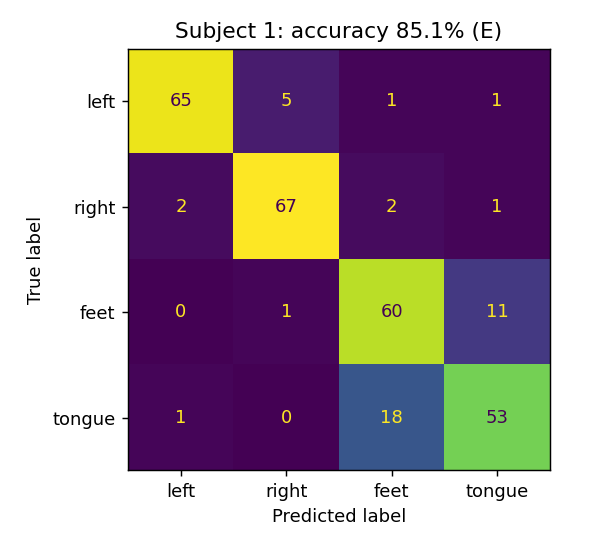

In [ ]:
from IPython.display import Image, display
display(Image("results_fb/confusion_s01.png"))

## 8. Downloading everything (weights, summary, plots)

In [ ]:
!zip -r results_fb.zip results_fb
from google.colab import files
files.download("results_fb.zip")

  adding: results_fb/ (stored 0%)
  adding: results_fb/summary.csv (deflated 57%)
  adding: results_fb/model_s04.npz (deflated 31%)
  adding: results_fb/confusion_s08.png (deflated 15%)
  adding: results_fb/confusion_s07.png (deflated 15%)
  adding: results_fb/confusion_s02.png (deflated 14%)
  adding: results_fb/model_s07.npz (deflated 31%)
  adding: results_fb/model_s02.npz (deflated 31%)
  adding: results_fb/model_s06.npz (deflated 30%)
  adding: results_fb/model_s08.npz (deflated 31%)
  adding: results_fb/confusion_s01.png (deflated 15%)
  adding: results_fb/confusion_s04.png (deflated 14%)
  adding: results_fb/model_s03.npz (deflated 31%)
  adding: results_fb/confusion_s05.png (deflated 14%)
  adding: results_fb/confusion_s06.png (deflated 15%)
  adding: results_fb/confusion_s03.png (deflated 14%)
  adding: results_fb/model_s05.npz (deflated 31%)
  adding: results_fb/model_s01.npz (deflated 31%)
  adding: results_fb/model_s09.npz (deflated 31%)
  adding: results_fb/confusion_s09.p

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>